## Preparing Data

In [1]:
import pandas as pd

fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

fake_df['label'] = 1 
true_df['label'] = 0   

df = pd.concat([fake_df, true_df], ignore_index=True)

print(df.shape)  
df.head()

(44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1


## Preprocessing

In [3]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
    return ' '.join(words)

df['content_clean'] = df['text'].apply(clean_text)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Training

In [5]:
from sklearn.model_selection import train_test_split

X = df['content_clean']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(35918,) (8980,)


## Encoding

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=10000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

## Logistic Regression

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.989086859688196
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4284
           1       0.99      0.99      0.99      4696

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



In [10]:
df['content_clean'] .head()

0    donald trump wish american happy new year leav...
1    house intelligence committee chairman devin nu...
2    friday, revealed former milwaukee sheriff davi...
3    christmas day, donald trump announced would ba...
4    pope francis used annual christmas day message...
Name: content_clean, dtype: str

## Word Cloud

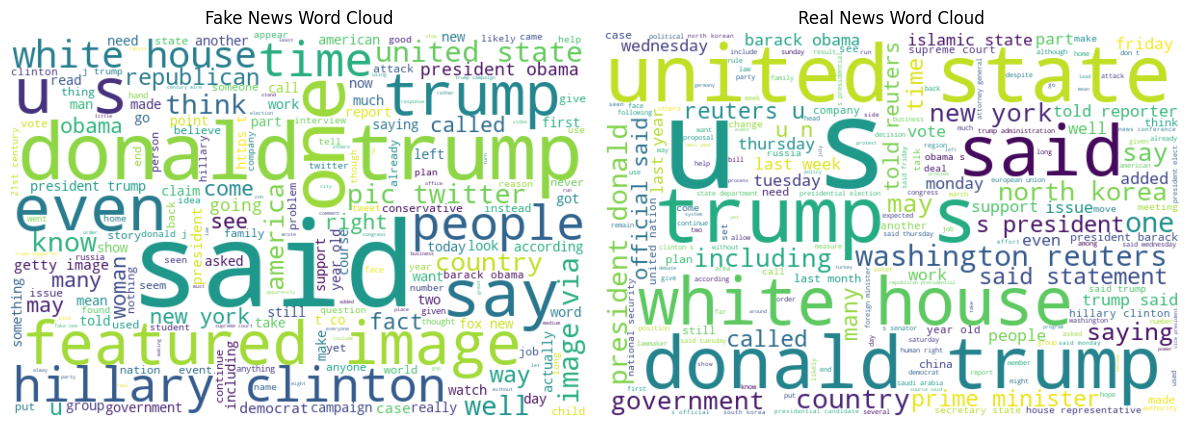

In [11]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

fake_text = ' '.join(df[df['label']==1]['content_clean'].fillna(''))
real_text = ' '.join(df[df['label']==0]['content_clean'].fillna(''))

plt.figure(figsize=(12,6))

# Fake News WordCloud
plt.subplot(1,2,1)
wc_fake = WordCloud(width=600, height=400, background_color='white', max_words=200).generate(fake_text)
plt.imshow(wc_fake, interpolation='bilinear')
plt.title('Fake News Word Cloud')
plt.axis('off')

# Real News WordCloud
plt.subplot(1,2,2)
wc_real = WordCloud(width=600, height=400, background_color='white', max_words=200).generate(real_text)
plt.imshow(wc_real, interpolation='bilinear')
plt.title('Real News Word Cloud')
plt.axis('off')

plt.tight_layout()
plt.show()